### Paired video / commentary embeddings from Qwen3.5-4B (LoRA checkpoint 50)

For every train and test take, two separate forward passes through the fine-tuned model:

- **Video**: the clip alone in a user turn (no system prompt, no text), mean-pooled over the video tokens.
- **Text**: the take's expert commentary alone (no video, no system prompt), mean-pooled over the commentary tokens.

Every decoder layer is pooled (cheap, done with hooks during the same forward pass) and cached;
the early / middle / late / last layers are then mean-centered per modality.

Finally, CCA fit on the train pairs finds the shared video/text subspace, scored on the held-out test pairs;
linear probes and forward-pass interventions then test which part of the video representation carries proficiency.

In [1]:
import json
import re
from pathlib import Path

# Same data layout and preprocessing as idea_1_midterm.ipynb.
DATA_ROOT = next(
    p / "data" for p in (Path.cwd(), *Path.cwd().parents) if (p / "data" / "annotations").is_dir()
)
ANNOTATION_ROOT = DATA_ROOT / "annotations"
COMMENTARY_ROOT = ANNOTATION_ROOT / "expert_commentary"

LEVELS = {
    "Novice": 1,
    "Early Expert": 2,
    "Intermediate Expert": 3,
    "Late Expert": 4,
}
VIDEO_TYPE = "ego"  # the view checkpoint 50 was fine-tuned on

# The commentary the model was trained on had the rating terms masked out; keep that.
RATING_TERMS = re.compile(
    r"\b(?:novice|early\s+expert|intermediate\s+expert|late\s+expert|"
    r"proficien\w*|rating|score|good\s+execution|tip\s+for\s+improvement|beginner)\b",
    flags=re.IGNORECASE,
)

def take_name(m):
    return m["video_paths"]["ego"].split("/")[1]

def video_path(m, video_type):
    parts = m["video_paths"][video_type].split("/")
    parts[-1:-1] = ["downscaled", "448"]
    return DATA_ROOT.joinpath(*parts)

def load_commentary(take):
    """The take's expert commentary in the training format (one block per expert), or None."""
    experts = []
    for data_path in sorted((COMMENTARY_ROOT / take).rglob("data.json")):
        transcript_path = data_path.parent / "transcriptions.json"
        if not transcript_path.exists():
            continue
        data = json.loads(data_path.read_text(encoding="utf-8"))
        transcripts = json.loads(transcript_path.read_text(encoding="utf-8"))
        segments = []
        for annotation in data.get("annotations", []):
            text = transcripts.get(annotation.get("recording_path"), {}).get("text", "").strip()
            if text:
                segments.append((annotation.get("video_time") or 0.0, RATING_TERMS.sub("[MASK]", text)))
        if segments:
            lines = "\n".join(f"[{t:.1f}s] {text}" for t, text in sorted(segments))
            experts.append(f"Expert {len(experts) + 1}:\n{lines}")
    if not experts:
        return None
    return "\n\n".join(experts)


with open("SkillFormer/annotation_test.jsonl", encoding="utf-8") as file:
    test_takes = {json.loads(line)["video_paths"][0].split("/")[1] for line in file}

def split_clips(split):
    """Takes with both a video and commentary. "train" is every train take; "test" is the val takes
    listed in SkillFormer/annotation_test.jsonl -- the same takes evaluate() scores in the midterm notebook."""
    annotation_file = "proficiency_demonstrator_train.json" if split == "train" else "proficiency_demonstrator_val.json"
    with open(ANNOTATION_ROOT / annotation_file, encoding="utf-8") as file:
        metadata = json.load(file)["annotations"]
    clips = []
    for m in metadata:
        if split == "test" and take_name(m) not in test_takes:
            continue
        if not video_path(m, VIDEO_TYPE).exists():
            continue
        commentary = load_commentary(take_name(m))
        if commentary is None:
            continue
        clips.append({"take_name": take_name(m), "scenario": m["scenario_name"],
                      "score": LEVELS[m["proficiency_score"]], "video": str(video_path(m, VIDEO_TYPE)),
                      "commentary": commentary})
    return clips

clips_by_split = {split: split_clips(split) for split in ("train", "test")}
clips = clips_by_split["test"]
for split, split_list in clips_by_split.items():
    print(f"{split}: {len(split_list)} clips with video and commentary")

train: 1174 clips with video and commentary
test: 164 clips with video and commentary


In [2]:
import torch
from peft import PeftModel
from transformers import AutoModelForMultimodalLM, AutoProcessor, BitsAndBytesConfig
from transformers.video_utils import load_video

model_id = "Qwen/Qwen3.5-4B"
CHECKPOINT = "./qwen35-4b-finetuned/checkpoint-50"
NUM_FRAMES = 16  # as in training
MAX_COMMENTARY_TOKENS = 6000  # as in training

bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.bfloat16,
    bnb_4bit_use_double_quant=True
)
base_model = AutoModelForMultimodalLM.from_pretrained(model_id, quantization_config=bnb_config, device_map="auto")
model = PeftModel.from_pretrained(base_model, CHECKPOINT).eval()
processor = AutoProcessor.from_pretrained(model_id)

# torchcodec can't load on this machine; decode with PyAV (see idea_1_midterm.ipynb).
def fetch_videos_pyav(video_url_or_urls, sample_indices_fn=None):
    if isinstance(video_url_or_urls, list):
        return list(zip(*[fetch_videos_pyav(x, sample_indices_fn) for x in video_url_or_urls]))
    return load_video(video_url_or_urls, backend="pyav", sample_indices_fn=sample_indices_fn)

processor.video_processor.fetch_videos = fetch_videos_pyav
processor.video_processor.fps = None  # fixed NUM_FRAMES instead of fps sampling

VIDEO_TOKEN_ID = processor.tokenizer.convert_tokens_to_ids("<|video_pad|>")

W1024 21:26:55.262000 3176 site-packages\torch\utils\flop_counter.py:113] triton not found; flop counting will not work for triton kernels


Loading weights:   0%|          | 0/723 [00:00<?, ?it/s]

In [3]:
# Mean-pool every decoder layer's output inside a forward hook, so the full (seq_len, 2560) hidden
# states of all 32 layers never have to be kept around. Layer k's entry is the residual stream after
# decoder layer k (1-indexed); the last one is taken before the final RMSNorm, like the others.
DECODER_LAYERS = [m for m in model.modules() if type(m).__name__ == "Qwen3_5DecoderLayer"]
assert len(DECODER_LAYERS) == base_model.config.text_config.num_hidden_layers

_pool_mask, _pooled = None, []

def _pool_hook(module, args, output):
    if _pool_mask is None:  # only pool inside layer_means(), not during the scoring runs further down
        return
    hidden = output[0] if isinstance(output, tuple) else output
    _pooled.append(hidden[0, _pool_mask].float().mean(0).cpu())

for layer in DECODER_LAYERS:
    layer.register_forward_hook(_pool_hook)

@torch.inference_mode()
def layer_means(batch, mask):
    """(num_layers, hidden) mean of each decoder layer's output over the positions where mask is True."""
    global _pool_mask
    assert mask.any(), "nothing to pool over"
    _pool_mask = mask.to(model.device)
    _pooled.clear()
    try:
        with torch.autocast("cuda", dtype=torch.bfloat16):  # training and evaluation ran under bf16 autocast
            model(**batch.to(model.device), logits_to_keep=1)
    finally:
        _pool_mask = None
    return torch.stack(_pooled)

def video_embedding(clip):
    """The clip alone, no text; pooled over the video tokens."""
    batch = processor.apply_chat_template(
        [{"role": "user", "content": [{"type": "video", "video": clip["video"]}]}],
        tokenize=True,
        return_dict=True,
        return_tensors="pt",
        processor_kwargs={"num_frames": NUM_FRAMES},
    )
    return layer_means(batch, batch["input_ids"][0] == VIDEO_TOKEN_ID)

def text_embedding(clip):
    """The commentary alone, in the training text block, no video; pooled over the commentary tokens."""
    commentary = clip["commentary"]
    ids = processor.tokenizer.encode(commentary, add_special_tokens=False)
    if len(ids) > MAX_COMMENTARY_TOKENS:
        commentary = processor.tokenizer.decode(ids[:MAX_COMMENTARY_TOKENS])
    prompt = processor.apply_chat_template(
        [{"role": "user", "content": [{"type": "text", "text": f"Expert commentary:\n{commentary}"}]}],
        tokenize=False,
    )
    start = prompt.index(commentary)
    end = start + len(commentary)
    batch = processor.tokenizer(prompt, return_tensors="pt", return_offsets_mapping=True)
    offsets = batch.pop("offset_mapping")[0]
    # Tokens that lie inside the commentary, so the chat markup and "Expert commentary:" header are left out.
    mask = (offsets[:, 0] >= start) & (offsets[:, 1] <= end) & (offsets[:, 1] > offsets[:, 0])
    return layer_means(batch, mask)

In [4]:
import contextlib

from tqdm.auto import tqdm

# Raw (uncentered) per-layer means for every clip, cached per split so an interrupted run resumes.
EMBEDDING_DIR = Path("embeddings")
EMBEDDING_DIR.mkdir(exist_ok=True)

def embed_split(split, adapter=True):
    """(video, text) raw embeddings for every clip of the split, each (clips, 32 layers, 2560).

    adapter=False embeds with the LoRA adapter disabled, i.e. with the zero-shot base model.
    """
    split_list = clips_by_split[split]
    model_name = Path(CHECKPOINT).name if adapter else "base"
    raw_path = EMBEDDING_DIR / f"qwen35_{model_name}_{split}_raw.pt"
    raw = torch.load(raw_path) if raw_path.exists() else {}
    todo = [clip for clip in split_list if clip["take_name"] not in raw]
    print(f"{model_name} {split}: {len(split_list) - len(todo)} clips already embedded, {len(todo)} to go")
    with contextlib.nullcontext() if adapter else model.disable_adapter():
        for k, clip in enumerate(tqdm(todo), 1):
            raw[clip["take_name"]] = {"video": video_embedding(clip), "text": text_embedding(clip)}
            if k % 10 == 0:
                torch.save(raw, raw_path)
    torch.save(raw, raw_path)
    return (torch.stack([raw[clip["take_name"]]["video"] for clip in split_list]),
            torch.stack([raw[clip["take_name"]]["text"] for clip in split_list]))

raw_embeddings = {split: embed_split(split) for split in ("test", "train")}
video_all, text_all = raw_embeddings["test"]
for split, (video, text) in raw_embeddings.items():
    print(f"{split} video: {tuple(video.shape)}, text: {tuple(text.shape)}")

checkpoint-50 test: 164 clips already embedded, 0 to go


0it [00:00, ?it/s]

checkpoint-50 train: 1174 clips already embedded, 0 to go


0it [00:00, ?it/s]

test video: (164, 32, 2560), text: (164, 32, 2560)
train video: (1174, 32, 2560), text: (1174, 32, 2560)


In [5]:
# Early, middle, late and last decoder layers (1-indexed). 31 is the latest layer whose output a later
# layer still reads, which the interventions further down need. Each modality's mean over the clips is subtracted, which removes the constant offset between video
# and text embeddings so the remaining structure can be compared.
LAYERS = {"early": 8, "middle": 16, "late": 31, "last": 32}

video_emb, text_emb = {}, {}
for name, layer in LAYERS.items():
    video = video_all[:, layer - 1]
    text = text_all[:, layer - 1]
    video_emb[name] = video - video.mean(0)
    text_emb[name] = text - text.mean(0)

paired_path = EMBEDDING_DIR / f"qwen35_{Path(CHECKPOINT).name}_test_paired.pt"
torch.save({
    "take_names": [clip["take_name"] for clip in clips],
    "scenarios": [clip["scenario"] for clip in clips],
    "scores": torch.tensor([clip["score"] for clip in clips]),
    "layers": LAYERS,
    "video": video_emb,  # {layer name: (clips, 2560)}, mean-centered
    "text": text_emb,
}, paired_path)
print(f"Saved {paired_path}")

Saved embeddings\qwen35_checkpoint-50_test_paired.pt


In [6]:
import torch.nn.functional as F

# Sanity check: cosine of each clip's video with its own commentary vs. with other clips'
# commentary, before and after centering, plus video -> text top-1 retrieval (chance = 1/clips).
print(f"{'layer':<8}{'':<10}{'matched':>9}{'mismatched':>12}{'top-1':>8}")
for name, layer in LAYERS.items():
    for label, video, text in [("raw", video_all[:, layer - 1], text_all[:, layer - 1]),
                               ("centered", video_emb[name], text_emb[name])]:
        sim = F.normalize(video, dim=-1) @ F.normalize(text, dim=-1).T
        matched = sim.diag().mean().item()
        mismatched = (sim.sum() - sim.diag().sum()).item() / (len(sim) ** 2 - len(sim))
        top1 = (sim.argmax(1) == torch.arange(len(sim))).float().mean().item()
        print(f"{name if label == 'raw' else '':<8}{label:<10}{matched:>9.3f}{mismatched:>12.3f}{top1:>8.3f}")
print(f"chance top-1: {1 / len(clips):.3f}")

layer               matched  mismatched   top-1
early   raw           0.816       0.802   0.055
        centered      0.311      -0.001   0.073
middle  raw           0.763       0.758   0.012
        centered      0.142      -0.000   0.049
late    raw           0.557       0.526   0.030
        centered      0.345      -0.002   0.079
last    raw           0.321       0.282   0.030
        centered      0.350      -0.001   0.079
chance top-1: 0.006


#### Shared subspace (CCA)

CCA is fit on the train pairs and scored on the held-out test pairs. With 2560-d features and ~1.2k
train clips, CCA on the raw features would find near-perfect correlations in pure noise, so each
modality is first reduced with PCA (fit on train; this also subtracts each modality's train mean).
In-sample train correlations are inflated by construction; the test correlations are the honest
measure, and the permutation floor (test video paired with shuffled test commentary) shows what
chance looks like with 164 test clips. Both modalities encode which scenario a take is from, and
with 6 scenarios that alone can give up to 5 near-perfect shared directions, so each component's
scenario eta² (share of its test variance that lies between scenarios) is reported too.

In [7]:
import numpy as np
from sklearn.cross_decomposition import CCA
from sklearn.decomposition import PCA

N_COMPONENTS = 32
PCA_DIMS = 128  # per modality, before CCA; exact SVD so reruns give identical results
N_PERMUTATIONS = 1000

def canonical_correlations(video_shared, text_shared):
    """Pearson correlation between each pair of canonical variates (one per component)."""
    v = video_shared - video_shared.mean(0)
    t = text_shared - text_shared.mean(0)
    return (v * t).sum(0) / np.sqrt((v ** 2).sum(0) * (t ** 2).sum(0))

def scenario_eta2(shared, scenarios):
    """Share of each canonical variate's variance that lies between scenarios (1 = pure scenario identity)."""
    within = sum(((shared[scenarios == s] - shared[scenarios == s].mean(0)) ** 2).sum(0) for s in np.unique(scenarios))
    return 1 - within / ((shared - shared.mean(0)) ** 2).sum(0)

test_scenarios = np.array([clip["scenario"] for clip in clips])

def fit_cca(raw_embeddings):
    """PCA + CCA on the train pairs at each layer in LAYERS, scored on the test pairs; prints a summary."""
    train_video_all, train_text_all = raw_embeddings["train"]
    video_all, text_all = raw_embeddings["test"]
    rng = np.random.default_rng(0)
    results = {}
    for name, layer in LAYERS.items():
        V_train = train_video_all[:, layer - 1].double().numpy()
        T_train = train_text_all[:, layer - 1].double().numpy()
        V_test = video_all[:, layer - 1].double().numpy()
        T_test = text_all[:, layer - 1].double().numpy()

        pca_video = PCA(PCA_DIMS, svd_solver="full").fit(V_train)
        pca_text = PCA(PCA_DIMS, svd_solver="full").fit(T_train)
        cca = CCA(n_components=N_COMPONENTS, max_iter=2000).fit(pca_video.transform(V_train), pca_text.transform(T_train))
        V_shared, T_shared = cca.transform(pca_video.transform(V_test), pca_text.transform(T_test))
        V_shared_train, T_shared_train = cca.transform(pca_video.transform(V_train), pca_text.transform(T_train))

        # The video canonical variates are affine in the embedding, u = (v - pca mean) @ directions + offset, so
        # the span of `directions` is the shared subspace in the model's 2560-d hidden-state space.
        directions = pca_video.components_.T @ (cca.x_rotations_ / cca._x_std[:, None])
        offset = -(cca._x_mean / cca._x_std) @ cca.x_rotations_
        assert np.allclose((V_test - pca_video.mean_) @ directions + offset, V_shared, atol=1e-6)

        test_corr = canonical_correlations(V_shared, T_shared)
        null = np.stack([canonical_correlations(V_shared, T_shared[rng.permutation(len(T_shared))])
                         for _ in range(N_PERMUTATIONS)])
        results[name] = {
            "layer": layer, "pca_video": pca_video, "pca_text": pca_text, "cca": cca,
            "mean": pca_video.mean_,  # train mean of the video embeddings
            "basis": np.linalg.qr(directions)[0],  # orthonormal (2560, N_COMPONENTS) basis of the shared subspace
            "V_shared": V_shared, "T_shared": T_shared,  # test clips projected onto the shared directions
            "train_corr": canonical_correlations(V_shared_train, T_shared_train),
            "test_corr": test_corr,
            "null_95": np.quantile(null, 0.95, axis=0),  # one-sided: 95th percentile of shuffled-pair correlations
            "scenario_eta2": scenario_eta2(V_shared, test_scenarios),
        }
        above = int((test_corr > results[name]["null_95"]).sum())
        print(f"{name} (layer {layer}): {above}/{N_COMPONENTS} components above the permutation 95th percentile")
        print("  component       " + "".join(f"{k:>6}" for k in range(1, 11)))
        print("  test r          " + "".join(f"{r:>6.2f}" for r in test_corr[:10]))
        print("  scenario eta2   " + "".join(f"{e:>6.2f}" for e in results[name]["scenario_eta2"][:10]))
    return results

cca_results = fit_cca(raw_embeddings)
train_video_all, train_text_all = raw_embeddings["train"]

early (layer 8): 30/32 components above the permutation 95th percentile
  component            1     2     3     4     5     6     7     8     9    10
  test r            1.00  0.99  0.99  0.99  0.97  0.91  0.92  0.92  0.87  0.83
  scenario eta2     0.99  0.99  0.99  0.98  0.95  0.05  0.01  0.01  0.04  0.04


middle (layer 16): 29/32 components above the permutation 95th percentile
  component            1     2     3     4     5     6     7     8     9    10
  test r            0.99  0.99  0.99  0.98  0.95  0.90  0.91  0.84  0.86  0.84
  scenario eta2     0.99  0.99  0.99  0.97  0.96  0.08  0.01  0.01  0.05  0.10


late (layer 31): 31/32 components above the permutation 95th percentile
  component            1     2     3     4     5     6     7     8     9    10
  test r            1.00  1.00  1.00  0.99  0.97  0.96  0.94  0.87  0.91  0.75
  scenario eta2     1.00  0.99  0.98  0.98  0.98  0.07  0.01  0.01  0.04  0.09


last (layer 32): 31/32 components above the permutation 95th percentile
  component            1     2     3     4     5     6     7     8     9    10
  test r            1.00  1.00  0.99  1.00  0.97  0.96  0.93  0.89  0.89  0.85
  scenario eta2     0.99  0.99  0.98  0.99  0.98  0.07  0.01  0.01  0.02  0.07


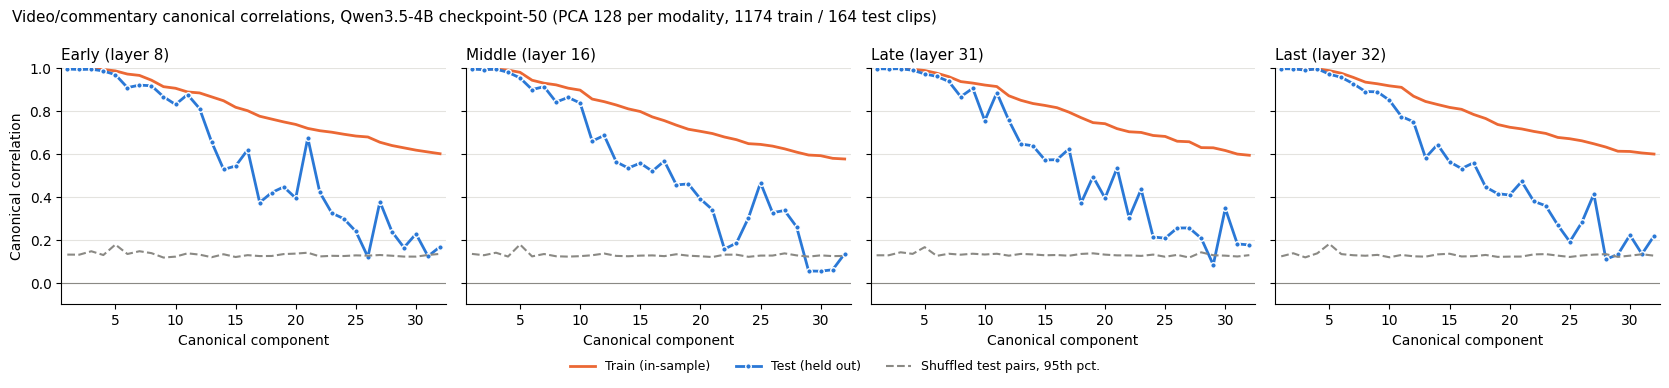

In [8]:
import matplotlib.pyplot as plt

TRAIN_COLOR, TEST_COLOR, NULL_COLOR = "#eb6834", "#2a78d6", "#8a8984"
components = np.arange(1, N_COMPONENTS + 1)

fig, axes = plt.subplots(1, len(cca_results), figsize=(4.2 * len(cca_results), 3.6), sharey=True)
for ax, (name, result) in zip(axes, cca_results.items()):
    ax.plot(components, result["train_corr"], color=TRAIN_COLOR, lw=2, label="Train (in-sample)")
    ax.plot(components, result["test_corr"], color=TEST_COLOR, lw=2, marker="o", ms=4,
            markeredgecolor="white", markeredgewidth=1, label="Test (held out)")
    ax.plot(components, result["null_95"], color=NULL_COLOR, lw=1.5, ls="--",
            label="Shuffled test pairs, 95th pct.")
    ax.axhline(0, color=NULL_COLOR, lw=0.8)
    ax.set_title(f"{name.capitalize()} (layer {result['layer']})", loc="left", fontsize=11)
    ax.set_xlabel("Canonical component")
    ax.set_xlim(0.5, N_COMPONENTS + 0.5)
    ax.grid(axis="y", color="#e4e3df", lw=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
axes[0].set_ylabel("Canonical correlation")
axes[0].set_ylim(min(-0.1, min(r["test_corr"].min() for r in cca_results.values()) - 0.05), 1.0)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, frameon=False, fontsize=9, ncol=3, loc="lower center", bbox_to_anchor=(0.5, -0.06))
fig.suptitle(f"Video/commentary canonical correlations, Qwen3.5-4B {Path(CHECKPOINT).name} "
             f"(PCA {PCA_DIMS} per modality, {len(clips_by_split['train'])} train / {len(clips)} test clips)",
             x=0.01, ha="left", fontsize=11)
fig.tight_layout()
Path("figures").mkdir(exist_ok=True)
fig.savefig(f"figures/cca_canonical_correlations_{Path(CHECKPOINT).name}.png", dpi=200, bbox_inches="tight")
plt.show()

#### Shared vs. residual: linear probes for proficiency

Each (train-mean-centered) video embedding is split into its orthogonal projection onto the span of
the 32 video-side canonical directions, mapped back from PCA space to the 2560-d embedding space
(**shared**), and what's left over (**residual**, which also keeps everything PCA dropped). The two
sum back to the centered embedding. Controls are projected the same way: onto the 128 principal components the
CCA works in (**PCA-128**), onto the top 32 of them (**top-32 PCA**: is the shared subspace just the high-variance
one?), and onto random 32-d subspaces of the PCA-128 space (**random**, averaged over 10 draws: are the CCA
directions better than any 32 directions CCA could have picked?). A logistic-regression probe is trained on each for the train
clips (regularization picked by 5-fold CV on train) and scored on the test clips. Since the shared
subspace is mostly scenario, a probe on scenario identity alone is the reference to beat.

In [9]:
from sklearn.linear_model import LogisticRegressionCV
from sklearn.metrics import accuracy_score, balanced_accuracy_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

train_scores = np.array([clip["score"] for clip in clips_by_split["train"]])
test_scores = np.array([clip["score"] for clip in clips])

PROBE_LAYERS = ("early", "middle", "last")
N_RANDOM_SUBSPACES = 10

def project(video, result, basis):
    """Train-mean-centered video embeddings projected onto the span of the orthonormal columns of basis."""
    return (video - result["mean"]) @ basis @ basis.T

def split_shared_residual(video, result):
    """(shared, residual) parts of video embeddings; shared + residual = video - train mean."""
    shared = project(video, result, result["basis"])
    return shared, video - result["mean"] - shared

def probe(train_x, test_x):
    """Test accuracy and balanced accuracy of a logistic-regression probe trained on the train clips."""
    model = make_pipeline(StandardScaler(), LogisticRegressionCV(Cs=np.logspace(-4, 2, 13), cv=5, max_iter=5000, n_jobs=-1))
    model.fit(train_x, train_scores)
    pred = model.predict(test_x)
    return accuracy_score(test_scores, pred), balanced_accuracy_score(test_scores, pred)

majority = np.bincount(train_scores).argmax()  # train's most common level, predicted for every test clip
# Each test clip gets the most common train level of its own scenario (ties go to the lower level).
train_scenarios = np.array([clip["scenario"] for clip in clips_by_split["train"]])
scenario_majority = {s: np.bincount(train_scores[train_scenarios == s]).argmax() for s in np.unique(train_scenarios)}
scenario_majority_pred = np.array([scenario_majority[clip["scenario"]] for clip in clips])
scenario_encoder = OneHotEncoder(handle_unknown="ignore").fit([[clip["scenario"]] for clip in clips_by_split["train"]])
probe_results = {
    "majority class": (accuracy_score(test_scores, np.full_like(test_scores, majority)),
                       balanced_accuracy_score(test_scores, np.full_like(test_scores, majority))),
    "per-scenario majority": (accuracy_score(test_scores, scenario_majority_pred),
                              balanced_accuracy_score(test_scores, scenario_majority_pred)),
    "scenario only": probe(scenario_encoder.transform([[clip["scenario"]] for clip in clips_by_split["train"]]).toarray(),
                           scenario_encoder.transform([[clip["scenario"]] for clip in clips]).toarray()),
}

def probe_representation(raw_embeddings, cca_results):
    """Probe results at each of PROBE_LAYERS for one model's video embeddings: the full embedding, its shared and
    residual parts, and the controls (the PCA-128 space CCA works in, its top 32 components, and random 32-d
    subspaces of it: mean and sd)."""
    train_video_all, video_all = raw_embeddings["train"][0], raw_embeddings["test"][0]
    results = {}
    for name in PROBE_LAYERS:
        result = cca_results[name]
        layer = result["layer"]
        train_video = train_video_all[:, layer - 1].double().numpy()
        test_video = video_all[:, layer - 1].double().numpy()
        train_shared, train_residual = split_shared_residual(train_video, result)
        test_shared, test_residual = split_shared_residual(test_video, result)
        results[f"{name} (layer {layer}): full"] = probe(train_video - result["mean"], test_video - result["mean"])
        results[f"{name} (layer {layer}): shared"] = probe(train_shared, test_shared)
        results[f"{name} (layer {layer}): residual"] = probe(train_residual, test_residual)
        pca_basis = result["pca_video"].components_.T  # (2560, PCA_DIMS), orthonormal, by decreasing variance
        results[f"{name} (layer {layer}): pca128"] = probe(project(train_video, result, pca_basis),
                                                          project(test_video, result, pca_basis))
        results[f"{name} (layer {layer}): pca32"] = probe(project(train_video, result, pca_basis[:, :N_COMPONENTS]),
                                                         project(test_video, result, pca_basis[:, :N_COMPONENTS]))
        random_results = []
        for seed in range(N_RANDOM_SUBSPACES):
            # A random orthonormal 32-d basis of the PCA-128 space, the space CCA picks its directions from.
            rotation = np.linalg.qr(np.random.default_rng(seed).standard_normal((PCA_DIMS, N_COMPONENTS)))[0]
            basis = pca_basis @ rotation
            random_results.append(probe(project(train_video, result, basis), project(test_video, result, basis)))
        results[f"{name} (layer {layer}): random"] = tuple(np.mean(random_results, axis=0))
        results[f"{name} (layer {layer}): random sd"] = tuple(np.std(random_results, axis=0))
    return results

probe_results.update(probe_representation(raw_embeddings, cca_results))

print(f"Proficiency probes on video embeddings ({len(train_scores)} train / {len(test_scores)} test clips)\n")
print(f"{'features':<28}{'accuracy':>10}{'balanced acc.':>15}")
for features, (acc, balanced) in probe_results.items():
    print(f"{features:<28}{acc:>10.3f}{balanced:>15.3f}")
print(f"\nChance balanced accuracy: 0.250; one test clip = {1 / len(test_scores):.3f} accuracy")

Proficiency probes on video embeddings (1174 train / 164 test clips)

features                      accuracy  balanced acc.
majority class                   0.354          0.250
per-scenario majority            0.433          0.445
scenario only                    0.433          0.445
early (layer 8): full            0.366          0.381
early (layer 8): shared          0.384          0.374
early (layer 8): residual        0.341          0.357
early (layer 8): pca128          0.402          0.453
early (layer 8): pca32           0.500          0.458
early (layer 8): random          0.418          0.403
early (layer 8): random sd       0.024          0.030
middle (layer 16): full          0.433          0.440
middle (layer 16): shared        0.494          0.440
middle (layer 16): residual      0.427          0.413
middle (layer 16): pca128        0.421          0.408
middle (layer 16): pca32         0.482          0.445
middle (layer 16): random        0.444          0.418
middle (laye

#### Shared vs. residual inside the forward pass

The test clips are scored video-only, with exactly the prompt of the midterm's video-only evaluation
(commentary replaced by the no-commentary placeholder), by the fine-tuned checkpoint and the zero-shot
base model. In the intervened runs, at one decoder layer the hidden states at the video-token positions
are replaced by the train mean plus only their **shared** part (projection onto the CCA subspace), or
plus only their **residual**; everything else in the forward pass is unchanged. The mean is kept
because removing it would wipe out the large constant component of the residual stream and break the
model in both conditions alike. Each model uses its own subspace, so the zero-shot model's embeddings
and CCA are computed first (with the adapter disabled). Layer 32 is left out: it is the last layer, so
no later layer reads the video tokens' layer-32 states and projecting them can't change the prediction;
layer 31, whose output layer 32 reads, is the latest point where an intervention can act.

In [10]:
# The zero-shot model's own shared subspace: the same embeddings and CCA with the LoRA adapter disabled.
raw_embeddings_base = {split: embed_split(split, adapter=False) for split in ("test", "train")}
cca_results_base = fit_cca(raw_embeddings_base)

base test: 164 clips already embedded, 0 to go


0it [00:00, ?it/s]

base train: 1174 clips already embedded, 0 to go


0it [00:00, ?it/s]

early (layer 8): 30/32 components above the permutation 95th percentile
  component            1     2     3     4     5     6     7     8     9    10
  test r            0.99  0.99  0.99  0.99  0.97  0.90  0.92  0.91  0.87  0.83
  scenario eta2     0.99  0.99  0.99  0.98  0.95  0.06  0.01  0.01  0.04  0.04


middle (layer 16): 29/32 components above the permutation 95th percentile
  component            1     2     3     4     5     6     7     8     9    10
  test r            0.99  0.99  0.99  0.98  0.95  0.90  0.91  0.83  0.82  0.88
  scenario eta2     0.99  0.99  0.99  0.97  0.95  0.09  0.01  0.01  0.06  0.08


late (layer 31): 32/32 components above the permutation 95th percentile
  component            1     2     3     4     5     6     7     8     9    10
  test r            1.00  1.00  1.00  0.99  0.97  0.96  0.94  0.85  0.90  0.78
  scenario eta2     1.00  0.99  0.98  0.98  0.98  0.07  0.01  0.01  0.03  0.09


last (layer 32): 29/32 components above the permutation 95th percentile
  component            1     2     3     4     5     6     7     8     9    10
  test r            1.00  1.00  1.00  0.99  0.97  0.96  0.93  0.87  0.90  0.83
  scenario eta2     1.00  0.99  0.99  0.98  0.97  0.07  0.01  0.01  0.03  0.07


In [11]:
# The same probes on the zero-shot model's own representations and shared subspace, then test accuracy for
# both models as a LaTeX table (booktabs; best per column in bold).
probe_results_base = probe_representation(raw_embeddings_base, cca_results_base)
probe_columns = {"Zero-shot": probe_results_base, "Fine-tuned": probe_results}
PARTS = {"full": "Full", "shared": "Shared (CCA)", "residual": "Residual", "pca128": "PCA-128",
         "pca32": "Top-32 PCA", "random": "Random 32-d in PCA-128"}
rows = [(f"{name} (layer {LAYERS[name]}): {part}", LAYERS[name], part) for name in PROBE_LAYERS for part in PARTS]

print(f"{'features':<32}" + "".join(f"{model_name:>12}" for model_name in probe_columns))
for key, _, part in rows:
    print(f"{key:<32}" + "".join(f"{results[key][0]:>12.3f}" for results in probe_columns.values()))
    if part == "random":
        print(f"{'  (sd over random subspaces)':<32}" + "".join(f"{results[key + ' sd'][0]:>12.3f}" for results in probe_columns.values()))
print(f"{'majority class':<32}{probe_results['majority class'][0]:>24.3f}")
print(f"{'per-scenario majority':<32}{probe_results['per-scenario majority'][0]:>24.3f}")

best = {model_name: max(round(results[key][0], 3) for key, _, _ in rows) for model_name, results in probe_columns.items()}

def cell(model_name, accuracy):
    return rf"\textbf{{{accuracy:.3f}}}" if round(accuracy, 3) == best[model_name] else f"{accuracy:.3f}"

latex = [
    r"\begin{table}[t]", r"\centering", r"\small",
    r"\caption{Test accuracy of logistic-regression probes predicting proficiency from Qwen3.5-4B video "
    rf"embeddings (mean-pooled over the video tokens after the given decoder layer), trained on the "
    rf"{len(train_scores):,} train takes and evaluated on the {len(test_scores)} test takes. Shared: projection "
    r"onto the model's 32-dimensional video--commentary CCA subspace; residual: the remainder; full: the "
    r"whole embedding; PCA-128: projection onto the 128 leading principal components of the train embeddings, "
    r"the space the CCA is fit in; top-32 PCA: onto the 32 leading ones; random 32-d in PCA-128: onto a random "
    rf"32-dimensional subspace of the PCA-128 space, averaged over {N_RANDOM_SUBSPACES} draws. "
    r"The zero-shot and fine-tuned (LoRA checkpoint 50) models each use their own embeddings and subspaces.}",
    r"\label{tab:shared-residual-probes}", r"\begin{tabular}{llcc}", r"\toprule",
    r"Layer & Representation & " + " & ".join(probe_columns) + r" \\", r"\midrule",
]
for k, (key, layer, part) in enumerate(rows):
    if part == "full" and k:
        latex.append(r"\midrule")
    latex.append(f"{layer if part == 'full' else ''} & {PARTS[part]} & "
                 + " & ".join(cell(model_name, results[key][0]) for model_name, results in probe_columns.items()) + r" \\")
latex += [r"\midrule", rf"Majority class & & \multicolumn{{2}}{{c}}{{{probe_results['majority class'][0]:.3f}}} \\",
          rf"Per-scenario majority & & \multicolumn{{2}}{{c}}{{{probe_results['per-scenario majority'][0]:.3f}}} \\",
          r"\bottomrule", r"\end{tabular}", r"\end{table}"]
print("\n" + "\n".join(latex))

features                           Zero-shot  Fine-tuned
early (layer 8): full                  0.372       0.366
early (layer 8): shared                0.402       0.384
early (layer 8): residual              0.366       0.341
early (layer 8): pca128                0.396       0.402
early (layer 8): pca32                 0.506       0.500
early (layer 8): random                0.440       0.418
  (sd over random subspaces)           0.024       0.024
middle (layer 16): full                0.476       0.433
middle (layer 16): shared              0.518       0.494
middle (layer 16): residual            0.463       0.427
middle (layer 16): pca128              0.457       0.421
middle (layer 16): pca32               0.476       0.482
middle (layer 16): random              0.442       0.444
  (sd over random subspaces)           0.038       0.027
last (layer 32): full                  0.445       0.427
last (layer 32): shared                0.476       0.488
last (layer 32): residual      

In [12]:
import csv

# Same prompt and scoring as predict() in idea_1_midterm.ipynb, video only.
SCORE_TOKENS = processor.tokenizer.convert_tokens_to_ids([str(s) for s in LEVELS.values()])
NO_COMMENTARY = "Expert commentary:\n(no commentary available)"
system_prompt = """You assess the proficiency of a performer from a video and an expert's commentary on that video.

Base your judgment on what is observable in the video. Use the commentary as supporting evidence about technique, not as a substitute for watching.

Proficiency scale:
1 - Novice
2 - Early Expert
3 - Intermediate Expert
4 - Late Expert

Respond in exactly this format and nothing else:
Score: <single digit 1-4>
"""

INTERVENTION_LAYERS = {name: layer for name, layer in LAYERS.items() if layer < len(DECODER_LAYERS)}
CONDITIONS = [("unmodified", None, None)] + [
    (f"{keep} only @ layer {layer}", name, keep) for name, layer in INTERVENTION_LAYERS.items() for keep in ("shared", "residual")
]
MODELS = {"fine-tuned": (contextlib.nullcontext, cca_results), "zero-shot": (model.disable_adapter, cca_results_base)}
SUBSPACES = {  # (model, layer name) -> (mean, basis) as float32 tensors on the GPU
    (model_name, name): tuple(torch.tensor(results[name][key], dtype=torch.float32, device=model.device)
                              for key in ("mean", "basis"))
    for model_name, (_, results) in MODELS.items() for name in INTERVENTION_LAYERS
}

_intervention = None  # {"layer", "mask", "mean", "basis", "keep"} while a projection is active

def _make_projection_hook(layer):
    def hook(module, args, output):
        if _intervention is None or _intervention["layer"] != layer:
            return None
        hidden = output[0] if isinstance(output, tuple) else output
        mask, mean, basis = _intervention["mask"], _intervention["mean"], _intervention["basis"]
        deviation = hidden[0, mask].float() - mean
        shared = deviation @ basis @ basis.T
        kept = shared if _intervention["keep"] == "shared" else deviation - shared
        hidden = hidden.clone()
        hidden[0, mask] = (mean + kept).to(hidden.dtype)
        return (hidden, *output[1:]) if isinstance(output, tuple) else hidden
    return hook

for handle in globals().get("_projection_handles", []):  # re-running this cell must not stack hooks
    handle.remove()
_projection_handles = [DECODER_LAYERS[layer - 1].register_forward_hook(_make_projection_hook(layer))
                       for layer in INTERVENTION_LAYERS.values()]

def video_only_batch(clip):
    """The video-only prompt on the GPU, the position whose logits predict the score digit, and the video-token mask."""
    messages = [
        {"role": "system", "content": [{"type": "text", "text": system_prompt}]},
        {"role": "user", "content": [{"type": "video", "video": clip["video"]}, {"type": "text", "text": NO_COMMENTARY}]},
        {"role": "assistant", "content": [{"type": "text", "text": "Score: 1"}]},
    ]
    batch = processor.apply_chat_template(
        [messages],
        tokenize=True,
        return_dict=True,
        return_tensors="pt",
        processor_kwargs={"padding": True, "num_frames": NUM_FRAMES},
    ).to(model.device)
    ids = batch["input_ids"][0].tolist()
    digit_pos = max(j for j, t in enumerate(ids) if t == SCORE_TOKENS[0])  # the placeholder digit
    assert processor.tokenizer.decode(ids[:digit_pos]).endswith("Score: "), "unexpected prompt layout"
    return batch, digit_pos, batch["input_ids"][0] == VIDEO_TOKEN_ID

@torch.inference_mode()
def score_probs(batch, digit_pos, intervention=None):
    """Probabilities for scores 1-4, optionally with a projection applied during the forward pass."""
    global _intervention
    _intervention = intervention
    try:
        with torch.autocast("cuda", dtype=torch.bfloat16):
            logits = model(**batch, logits_to_keep=batch["input_ids"].shape[1] - digit_pos + 1).logits[0, 0]
    finally:
        _intervention = None
    return logits[SCORE_TOKENS].float().softmax(-1).tolist()

# One row per clip x model x condition, appended as clips finish; re-running resumes and only scores the
# (clip, model, condition) runs that are missing, e.g. after adding a layer.
intervention_path = Path(f"eval_interventions_{Path(CHECKPOINT).name}_test_video_only.csv")
fields = ["take_name", "scenario", "true", "model", "condition", "pred", "p1", "p2", "p3", "p4"]
done = set()
if intervention_path.exists():
    with open(intervention_path, newline="", encoding="utf-8") as file:
        done = {(row["take_name"], row["model"], row["condition"]) for row in csv.DictReader(file)}
runs = [(model_name, condition) for model_name in MODELS for condition, _, _ in CONDITIONS]
todo = [clip for clip in clips if any((clip["take_name"], *run) not in done for run in runs)]
print(f"{len(done)} runs already scored; {len(todo)} clips still missing some of the "
      f"{len(MODELS)} models x {len(CONDITIONS)} conditions")

write_header = not intervention_path.exists()
with open(intervention_path, "a", newline="", encoding="utf-8") as file:
    writer = csv.DictWriter(file, fieldnames=fields)
    if write_header:
        writer.writeheader()
    for clip in tqdm(todo):
        batch, digit_pos, video_mask = video_only_batch(clip)
        rows = []
        for model_name, (adapter_context, _) in MODELS.items():
            with adapter_context():
                for condition, layer_name, keep in CONDITIONS:
                    if (clip["take_name"], model_name, condition) in done:
                        continue
                    intervention = None
                    if layer_name is not None:
                        mean, basis = SUBSPACES[model_name, layer_name]
                        intervention = {"layer": LAYERS[layer_name], "mask": video_mask, "mean": mean,
                                        "basis": basis, "keep": keep}
                    probs = score_probs(batch, digit_pos, intervention)
                    rows.append({"take_name": clip["take_name"], "scenario": clip["scenario"], "true": clip["score"],
                                 "model": model_name, "condition": condition,
                                 "pred": 1 + max(range(4), key=probs.__getitem__),
                                 **{f"p{s}": f"{p:.4f}" for s, p in zip(LEVELS.values(), probs)}})
        writer.writerows(rows)
        file.flush()

2296 runs already scored; 0 clips still missing some of the 2 models x 7 conditions


0it [00:00, ?it/s]

In [13]:
from collections import defaultdict

with open(intervention_path, newline="", encoding="utf-8") as file:
    intervention_rows = list(csv.DictReader(file))
by_run = defaultdict(dict)  # (model, condition) -> {take_name: row}
for row in intervention_rows:
    by_run[row["model"], row["condition"]][row["take_name"]] = row
take_names = [clip["take_name"] for clip in clips]
true = np.array([clip["score"] for clip in clips])

# The unmodified runs should reproduce the midterm's video-only evaluation of the same clips.
midterm_csvs = {"fine-tuned": f"eval_{Path(CHECKPOINT).name}_test_video_only.csv", "zero-shot": "eval_base_test_video_only.csv"}
for model_name, midterm_csv in midterm_csvs.items():
    with open(midterm_csv, newline="", encoding="utf-8") as file:
        midterm = {row["take_name"]: row["pred"] for row in csv.DictReader(file)}
    same = sum(by_run[model_name, "unmodified"][t]["pred"] == midterm[t] for t in take_names)
    print(f"{model_name} unmodified vs. {midterm_csv}: same prediction on {same}/{len(take_names)} clips")

print(f"\nVideo-only proficiency accuracy on {len(take_names)} test clips\n")
print(f"{'model':<12}{'condition':<26}{'accuracy':>10}{'balanced acc.':>15}{'predicted N/E/I/L':>20}{'same as unmodified':>20}")
for model_name in MODELS:
    unmodified = np.array([int(by_run[model_name, "unmodified"][t]["pred"]) for t in take_names])
    for condition, _, _ in CONDITIONS:
        pred = np.array([int(by_run[model_name, condition][t]["pred"]) for t in take_names])
        counts = "/".join(str(int((pred == s).sum())) for s in LEVELS.values())
        print(f"{model_name:<12}{condition:<26}{accuracy_score(true, pred):>10.3f}"
              f"{balanced_accuracy_score(true, pred):>15.3f}{counts:>20}{(pred == unmodified).mean():>20.3f}")
majority_level = np.bincount(true).argmax()
print(f"\nMajority class (always {majority_level}): {(true == majority_level).mean():.3f} accuracy, 0.250 balanced")

fine-tuned unmodified vs. eval_checkpoint-50_test_video_only.csv: same prediction on 146/164 clips
zero-shot unmodified vs. eval_base_test_video_only.csv: same prediction on 153/164 clips

Video-only proficiency accuracy on 164 test clips

model       condition                   accuracy  balanced acc.   predicted N/E/I/L  same as unmodified
fine-tuned  unmodified                     0.305          0.289          0/120/40/4               1.000
fine-tuned  shared only @ layer 8          0.256          0.259          0/145/9/10               0.762
fine-tuned  residual only @ layer 8        0.305          0.294          0/124/34/6               0.902
fine-tuned  shared only @ layer 16         0.256          0.257          0/135/25/4               0.835
fine-tuned  residual only @ layer 16       0.274          0.267          0/128/30/6               0.915
fine-tuned  shared only @ layer 31         0.293          0.276          0/117/42/5               0.927
fine-tuned  residual only @ laye